<a href="https://colab.research.google.com/github/2303a51210/quantum_computing_project/blob/main/Photonic_Quantum_GAN_Complete(45_PRBLM).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Photonic Quantum GAN (PQGAN)

This notebook trains a one-mode continuous-variable photonic generator using Strawberry Fields' Fock simulator on the D25 Gaussian-mixture and D36 Beta(2,5) datasets.

**Before running:** execute the installation cell, then run the main code cell. If the CSV files are not already in `/content`, Colab will ask you to upload both files.

**Measurement note:** the Fock backend in this setup does not support `MeasureX` with a `shots` argument. The notebook therefore calculates the simulated X-quadrature probability distribution and draws numerical samples from it. These are simulated samples, not physical hardware shots.

In [1]:
# Install required libraries in Google Colab
!pip install strawberryfields torch scipy pandas matplotlib scikit-learn -q


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/strawberryfields/apps/data/sample.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


PHOTONIC QUANTUM GAN - PROJECT CONFIGURATION
Device: cpu
Simulator: Strawberry Fields Fock backend
Photonic modes: 1
Qubits: 0
Data encoding: Continuous-variable X-quadrature sampling with trainable affine scale and shift
Optical gate depth: 3
Fock cutoff: 10
Note: Fock backend uses numerical quadrature sampling.
These are simulated samples, not physical hardware shots.

Dataset: Gaussian Mixture (D25)
CSV file: D25_gaussian_mixture.csv
Number of samples: 12000
Mean: -0.009096
Standard deviation: 1.835304

Dataset: Beta(2,5) (D36)
CSV file: D36_beta_2_5.csv
Number of samples: 12000
Mean: 0.287065
Standard deviation: 0.160673


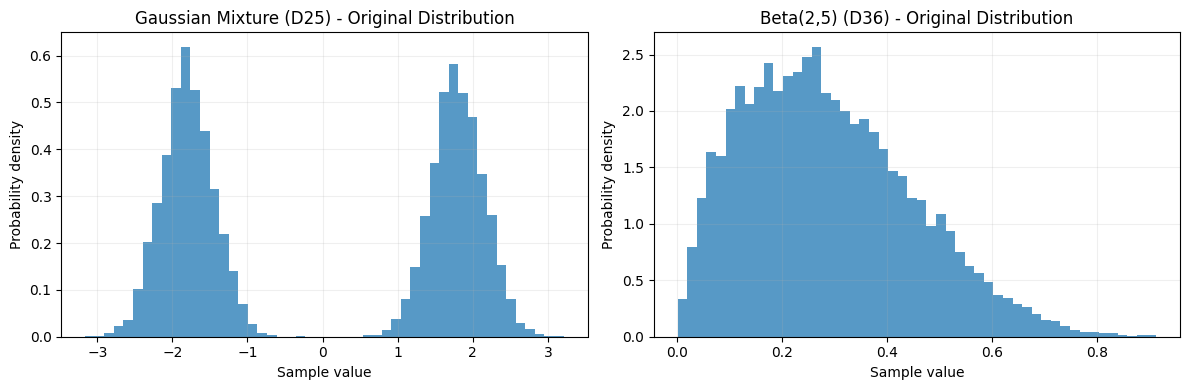


TRAINING: Gaussian Mixture (D25)
Epoch 005/30 | Discriminator loss: -0.000062 | Generator objective: 0.001677
Epoch 010/30 | Discriminator loss: -0.000052 | Generator objective: 0.001687
Epoch 015/30 | Discriminator loss: -0.000069 | Generator objective: 0.001744
Epoch 020/30 | Discriminator loss: -0.000085 | Generator objective: 0.001732
Epoch 025/30 | Discriminator loss: -0.000063 | Generator objective: 0.001749
Epoch 030/30 | Discriminator loss: 0.000015 | Generator objective: 0.001697

========== PERFORMANCE RESULTS ==========
Wasserstein-1 distance: 0.846314
MMD: 0.180228
Mode coverage: 100.00%
Mean photon number: 0.061596
Estimated truncation probability beyond cutoff 10: 0.00000001

========== QUANTUM RESOURCE COST ==========
Qubits: 0
Photonic modes: 1
Optical gate depth: 3
Measurement/readout step: 1
Fock cutoff dimension: 10
Training samples per generator call: 64
Final generation samples: 1000
Circuit evaluations: 151
Total simulated quadrature samples: 10600
Training time:

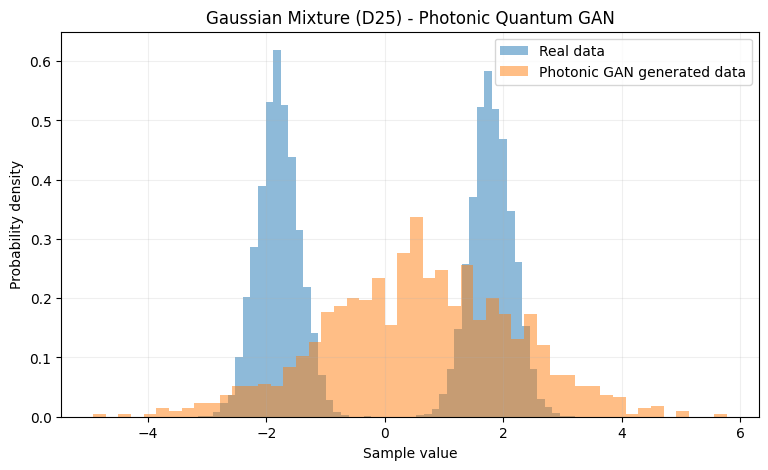


TRAINING: Beta(2,5) (D36)
Epoch 005/30 | Discriminator loss: -0.000036 | Generator objective: -0.009741
Epoch 010/30 | Discriminator loss: -0.000069 | Generator objective: -0.009669
Epoch 015/30 | Discriminator loss: -0.000124 | Generator objective: -0.009675
Epoch 020/30 | Discriminator loss: -0.000022 | Generator objective: -0.009596
Epoch 025/30 | Discriminator loss: -0.000218 | Generator objective: -0.009639
Epoch 030/30 | Discriminator loss: -0.000297 | Generator objective: -0.009516

========== PERFORMANCE RESULTS ==========
Wasserstein-1 distance: 0.058350
MMD: 0.002733
Mode coverage: 83.33%
Mean photon number: 0.061300
Estimated truncation probability beyond cutoff 10: 0.00000001

========== QUANTUM RESOURCE COST ==========
Qubits: 0
Photonic modes: 1
Optical gate depth: 3
Measurement/readout step: 1
Fock cutoff dimension: 10
Training samples per generator call: 64
Final generation samples: 1000
Circuit evaluations: 151
Total simulated quadrature samples: 10600
Training time: 

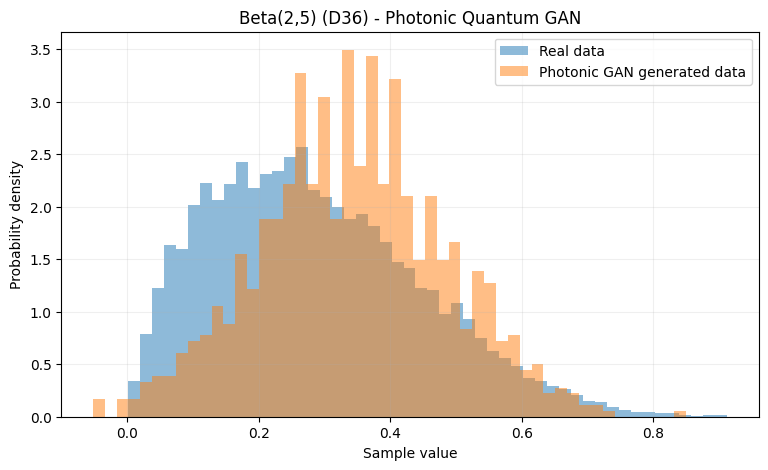


========== FINAL PQGAN COMPARISON ==========


,Dataset,Wasserstein-1,MMD,Mode Coverage (%),Mean Photon Number,Truncation Probability,Qubits,Photonic Modes,Circuit Depth,Fock Cutoff,Circuit Evaluations,Simulated Quadrature Samples,Training Time (seconds),Inference Time (seconds)
0,Gaussian Mixture (D25),0.846314,0.180228,100.000000,0.061596,5.204277e-09,0,1,3,10,151,10600,24.459648,0.122930
1,"Beta(2,5) (D36)",0.058350,0.002733,83.333333,0.061300,5.145540e-09,0,1,3,10,151,10600,20.060713,0.732049


Saved: Gaussian_Mixture_D25_generated_samples.csv
Saved: Beta25_D36_generated_samples.csv
Saved: PQGAN_Final_Results.csv

PQGAN NOTEBOOK EXECUTION COMPLETED
Both datasets have been processed.


In [2]:
# ============================================================
# PHOTONIC QUANTUM GAN (PQGAN)
# D25: One-Dimensional Gaussian Mixture
# D36: Beta(2,5) Continuous Distribution
# Photonic simulator: Strawberry Fields Fock backend
# ============================================================

# 1. IMPORT LIBRARIES AND COMPATIBILITY

import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import scipy.integrate

# Compatibility for Strawberry Fields versions that still call simps.
if not hasattr(scipy.integrate, "simps"):
    scipy.integrate.simps = scipy.integrate.simpson

import torch
import torch.nn as nn
import torch.optim as optim

import strawberryfields as sf
from strawberryfields import ops

from scipy.stats import wasserstein_distance
from scipy.signal import find_peaks
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore")

# ============================================================
# 2. PROJECT SETTINGS
# ============================================================

SEED = 42
ITERATIONS = 30             # Increase to 60 for longer training
BATCH_SIZE = 64             # Simulated quadrature samples per training call
GENERATED_SAMPLES = 1000    # Number of final generated samples
CUTOFF = 10                 # Fock-space cutoff dimension

# Photonic resource declarations
PHOTONIC_MODES = 1
QUBITS = 0
PHOTONIC_GATE_DEPTH = 3     # Sgate -> Dgate -> Kgate
MEASUREMENT_STEPS = 1       # Numerical homodyne X-quadrature readout

# Continuous-variable encoding declaration:
# A generated continuous scalar is obtained from the optical X quadrature.
# A trainable affine transformation (scale and shift) maps it to data space.
ENCODING_METHOD = (
    "Continuous-variable X-quadrature sampling with trainable affine "
    "scale and shift"
)

np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("================================================")
print("PHOTONIC QUANTUM GAN - PROJECT CONFIGURATION")
print("================================================")
print("Device:", DEVICE)
print("Simulator: Strawberry Fields Fock backend")
print("Photonic modes:", PHOTONIC_MODES)
print("Qubits:", QUBITS)
print("Data encoding:", ENCODING_METHOD)
print("Optical gate depth:", PHOTONIC_GATE_DEPTH)
print("Fock cutoff:", CUTOFF)
print("Note: Fock backend uses numerical quadrature sampling.")
print("These are simulated samples, not physical hardware shots.")

# ============================================================
# 3. FIND AND LOAD THE TWO CSV DATASETS
# ============================================================

REQUIRED_FILES = [
    "D25_gaussian_mixture.csv",
    "D36_beta_2_5.csv"
]

def find_dataset_files():
    """Search common Google Colab, Kaggle, and local upload folders."""
    found = {}
    search_locations = ["/content", "/kaggle/input", "/mnt/data"]

    for folder in search_locations:
        if os.path.exists(folder):
            for root, dirs, files in os.walk(folder):
                for filename in REQUIRED_FILES:
                    if filename in files and filename not in found:
                        found[filename] = os.path.join(root, filename)

    return found

dataset_files = find_dataset_files()

# If files are not found, open the Google Colab upload dialog.
missing_files = [f for f in REQUIRED_FILES if f not in dataset_files]

if missing_files:
    try:
        from google.colab import files
        print("Please upload both dataset CSV files:")
        uploaded = files.upload()
        dataset_files = find_dataset_files()
    except ImportError:
        pass

missing_files = [f for f in REQUIRED_FILES if f not in dataset_files]

if missing_files:
    raise FileNotFoundError(
        "Missing dataset file(s): " + ", ".join(missing_files) +
        ". Upload D25_gaussian_mixture.csv and D36_beta_2_5.csv."
    )

DATASET_PATHS = {
    "Gaussian Mixture (D25)": dataset_files["D25_gaussian_mixture.csv"],
    "Beta(2,5) (D36)": dataset_files["D36_beta_2_5.csv"]
}

data = {}

for dataset_name, csv_path in DATASET_PATHS.items():

    df = pd.read_csv(csv_path)

    if "sample" not in df.columns:
        raise ValueError(
            f"{os.path.basename(csv_path)} must contain a column named 'sample'. "
            f"Found columns: {list(df.columns)}"
        )

    samples = df["sample"].dropna().to_numpy(dtype=np.float32)

    if len(samples) < 2:
        raise ValueError(f"{dataset_name} has fewer than two valid samples.")

    mean_value = float(np.mean(samples))
    std_value = float(np.std(samples))

    if std_value < 1e-8:
        raise ValueError(f"{dataset_name} has almost zero standard deviation.")

    normalized_samples = (samples - mean_value) / std_value

    data[dataset_name] = {
        "original": samples,
        "normalized": normalized_samples,
        "mean": mean_value,
        "std": std_value
    }

    print("\nDataset:", dataset_name)
    print("CSV file:", os.path.basename(csv_path))
    print("Number of samples:", len(samples))
    print("Mean:", round(mean_value, 6))
    print("Standard deviation:", round(std_value, 6))

# ============================================================
# 4. VISUALIZE ORIGINAL DATASETS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, dataset) in zip(axes, data.items()):
    ax.hist(
        dataset["original"],
        bins=50,
        density=True,
        alpha=0.75
    )
    ax.set_title(name + " - Original Distribution")
    ax.set_xlabel("Sample value")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ============================================================
# 5. PHOTONIC QUANTUM GENERATOR
# ============================================================

def quantum_generator(theta, n_samples, cutoff=CUTOFF):
    """
    Simulate a one-mode photonic circuit and sample its X-quadrature PDF.

    The Fock backend does not support MeasureX with shots in this setup.
    Therefore, the circuit is simulated without a measurement operation.
    Strawberry Fields calculates the continuous X-quadrature probability
    distribution, and samples are drawn numerically from that distribution.
    """

    # Trainable photonic gate parameters
    kerr = 0.3 * np.tanh(theta[0])
    squeeze = 1.0 * np.tanh(theta[1])
    displacement = 1.5 * np.tanh(theta[2])

    # Trainable output scale and shift
    scale = np.exp(0.5 * np.tanh(theta[3]))
    shift = 0.5 * np.tanh(theta[4])

    # Quadrature grids; moderate grid sizes reduce simulation time.
    x_grid = np.linspace(-6.0, 6.0, 401)
    p_grid = np.linspace(-8.0, 8.0, 161)

    # Build a one-mode optical circuit.
    circuit = sf.Program(PHOTONIC_MODES)

    with circuit.context as q:
        ops.Sgate(squeeze) | q[0]       # Squeezing gate
        ops.Dgate(displacement) | q[0]  # Displacement gate
        ops.Kgate(kerr) | q[0]          # Kerr nonlinear gate

    # Run the Fock-space simulator.
    engine = sf.Engine(
        "fock",
        backend_options={"cutoff_dim": cutoff}
    )
    result = engine.run(circuit)
    state = result.state

    # Get the discretized continuous X-quadrature probability density.
    probabilities = np.asarray(
        state.x_quad_values(0, x_grid, p_grid),
        dtype=np.float64
    ).reshape(-1)

    probabilities = np.nan_to_num(
        probabilities,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )
    probabilities = np.maximum(probabilities, 0.0)

    probability_sum = probabilities.sum()

    if not np.isfinite(probability_sum) or probability_sum <= 0:
        raise RuntimeError(
            "The photonic X-quadrature probability distribution is invalid. "
            "Try increasing CUTOFF or checking the gate parameters."
        )

    # np.random.choice requires discrete normalized probabilities.
    probabilities /= probability_sum

    # Draw continuous-variable samples on the quadrature grid.
    x_samples = np.random.choice(
        x_grid,
        size=n_samples,
        replace=True,
        p=probabilities
    )

    # Map quadrature samples into the model's output range.
    generated = scale * x_samples + shift

    return generated.astype(np.float32)


# ============================================================
# 6. CLASSICAL DISCRIMINATOR
# ============================================================

class Discriminator(nn.Module):
    """Classical neural network that scores real and generated samples."""

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================
# 7. MAXIMUM MEAN DISCREPANCY (MMD)
# ============================================================

def calculate_mmd(real, generated):
    """Calculate unbiased MMD using a Gaussian RBF kernel."""

    real = np.asarray(real, dtype=np.float64).reshape(-1, 1)
    generated = np.asarray(generated, dtype=np.float64).reshape(-1, 1)

    def rbf_kernel(x, y):
        squared_distances = cdist(x, y, metric="sqeuclidean")
        return np.exp(-squared_distances / 2.0)

    n = len(real)
    m = len(generated)

    if n < 2 or m < 2:
        return float("nan")

    k_xx = rbf_kernel(real, real)
    k_yy = rbf_kernel(generated, generated)
    k_xy = rbf_kernel(real, generated)

    xx = (k_xx.sum() - np.trace(k_xx)) / (n * (n - 1))
    yy = (k_yy.sum() - np.trace(k_yy)) / (m * (m - 1))
    xy = k_xy.mean()

    # Small negative values can occur due to finite-sample estimation.
    return float(max(0.0, xx + yy - 2.0 * xy))


# ============================================================
# 8. MODE COVERAGE
# ============================================================

def calculate_mode_coverage(real, generated):
    """
    Estimate the fraction of peaks in the real histogram that have a
    nearby generated-data peak. This is a histogram-based estimate.
    """

    real = np.asarray(real)
    generated = np.asarray(generated)

    real_hist, bins = np.histogram(real, bins=60, density=True)
    centers = (bins[:-1] + bins[1:]) / 2

    real_peaks, _ = find_peaks(
        real_hist,
        prominence=max(0.05 * np.max(real_hist), 1e-8)
    )

    if len(real_peaks) == 0:
        return float("nan")

    generated_hist, _ = np.histogram(
        generated,
        bins=bins,
        density=True
    )

    generated_peaks, _ = find_peaks(
        generated_hist,
        prominence=max(0.05 * np.max(generated_hist), 1e-8)
    )

    if len(generated_peaks) == 0:
        return 0.0

    real_modes = centers[real_peaks]
    generated_modes = centers[generated_peaks]

    # Allow a match within two histogram-bin widths.
    tolerance = 2.0 * (bins[1] - bins[0])

    covered = sum(
        np.min(np.abs(generated_modes - mode)) <= tolerance
        for mode in real_modes
    )

    return float(covered / len(real_modes))


# ============================================================
# 9. MEAN PHOTON NUMBER AND TRUNCATION DIAGNOSTIC
# ============================================================

def photon_diagnostics(theta, cutoff):
    """
    Calculate mean photon number and estimate probability in Fock levels
    at or above the requested cutoff using a larger reference cutoff.
    """

    kerr = 0.3 * np.tanh(theta[0])
    squeeze = 1.0 * np.tanh(theta[1])
    displacement = 1.5 * np.tanh(theta[2])

    reference_cutoff = cutoff + 20

    circuit = sf.Program(1)

    with circuit.context as q:
        ops.Sgate(squeeze) | q[0]
        ops.Dgate(displacement) | q[0]
        ops.Kgate(kerr) | q[0]

    engine = sf.Engine(
        "fock",
        backend_options={"cutoff_dim": reference_cutoff}
    )

    result = engine.run(circuit)

    fock_probabilities = np.asarray(
        result.state.all_fock_probs(),
        dtype=np.float64
    ).reshape(-1)

    total_probability = fock_probabilities.sum()

    if total_probability <= 0:
        raise RuntimeError("Invalid Fock-state probabilities.")

    # Normalize within the larger reference cutoff.
    fock_probabilities /= total_probability

    photon_numbers = np.arange(len(fock_probabilities))

    mean_photons = np.sum(
        photon_numbers * fock_probabilities
    )

    # Probability mass in levels excluded by the requested cutoff.
    truncation_probability = np.sum(
        fock_probabilities[cutoff:]
    )

    return float(mean_photons), float(truncation_probability)


# ============================================================
# 10. TRAIN THE PHOTONIC QUANTUM GAN
# ============================================================

def train_pqgan(name, dataset):

    print("\n" + "=" * 60)
    print("TRAINING:", name)
    print("=" * 60)

    real_data = dataset["normalized"]

    real_tensor = torch.tensor(
        real_data,
        dtype=torch.float32,
        device=DEVICE
    ).reshape(-1, 1)

    # Five trainable photonic/output parameters:
    # theta[0] = Kerr, theta[1] = squeezing,
    # theta[2] = displacement, theta[3] = output scale,
    # theta[4] = output shift.
    theta = np.array(
        [0.1, 0.2, 0.1, 0.1, 0.0],
        dtype=np.float64
    )

    discriminator = Discriminator().to(DEVICE)

    optimizer_D = optim.Adam(
        discriminator.parameters(),
        lr=0.0005
    )

    generator_lr = 0.03
    critic_steps = 3

    circuit_evaluations = 0
    simulated_quadrature_samples = 0

    training_start = time.time()

    # --------------------------------------------------------
    # Adversarial training
    # --------------------------------------------------------

    for epoch in range(ITERATIONS):

        # Train the discriminator several times per epoch.
        for _ in range(critic_steps):

            indices = torch.randint(
                0,
                len(real_tensor),
                (BATCH_SIZE,),
                device=DEVICE
            )

            real_batch = real_tensor[indices]

            fake_np = quantum_generator(theta, BATCH_SIZE)

            circuit_evaluations += 1
            simulated_quadrature_samples += BATCH_SIZE

            fake_batch = torch.tensor(
                fake_np,
                dtype=torch.float32,
                device=DEVICE
            ).reshape(-1, 1)

            optimizer_D.zero_grad()

            real_score = discriminator(real_batch).mean()
            fake_score = discriminator(fake_batch.detach()).mean()

            # Wasserstein discriminator objective.
            loss_D = fake_score - real_score

            loss_D.backward()
            optimizer_D.step()

            # Weight clipping used by the basic WGAN formulation.
            for parameter in discriminator.parameters():
                parameter.data.clamp_(-0.01, 0.01)

        # ----------------------------------------------------
        # SPSA optimization of photonic parameters
        # ----------------------------------------------------

        epsilon = 0.05

        delta = np.random.choice(
            [-1.0, 1.0],
            size=len(theta)
        )

        theta_plus = theta + epsilon * delta
        theta_minus = theta - epsilon * delta

        fake_plus = quantum_generator(theta_plus, BATCH_SIZE)
        circuit_evaluations += 1
        simulated_quadrature_samples += BATCH_SIZE

        fake_minus = quantum_generator(theta_minus, BATCH_SIZE)
        circuit_evaluations += 1
        simulated_quadrature_samples += BATCH_SIZE

        with torch.no_grad():

            plus_tensor = torch.tensor(
                fake_plus,
                dtype=torch.float32,
                device=DEVICE
            ).reshape(-1, 1)

            minus_tensor = torch.tensor(
                fake_minus,
                dtype=torch.float32,
                device=DEVICE
            ).reshape(-1, 1)

            loss_plus = -discriminator(plus_tensor).mean().item()
            loss_minus = -discriminator(minus_tensor).mean().item()

        # SPSA gradient estimate.
        gradient = (
            (loss_plus - loss_minus) / (2.0 * epsilon)
        ) * delta

        theta -= generator_lr * gradient

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch + 1:03d}/{ITERATIONS} | "
                f"Discriminator loss: {loss_D.item():.6f} | "
                f"Generator objective: {(loss_plus + loss_minus) / 2:.6f}"
            )

    training_time = time.time() - training_start

    # --------------------------------------------------------
    # Generate new samples and measure inference time
    # --------------------------------------------------------

    inference_start = time.time()

    generated_normalized = quantum_generator(
        theta,
        GENERATED_SAMPLES
    )

    inference_time = time.time() - inference_start

    circuit_evaluations += 1
    simulated_quadrature_samples += GENERATED_SAMPLES

    # Return samples to the original data scale.
    generated = (
        generated_normalized * dataset["std"]
        + dataset["mean"]
    )

    # --------------------------------------------------------
    # Evaluation metrics
    # --------------------------------------------------------

    real = dataset["original"]

    w1 = wasserstein_distance(real, generated)

    # Use equal-sized subsets for the MMD calculation.
    mmd_sample_count = min(2000, len(real), len(generated))

    mmd = calculate_mmd(
        real[:mmd_sample_count],
        generated[:mmd_sample_count]
    )

    mode_coverage = calculate_mode_coverage(
        real,
        generated
    )

    mean_photons, truncation_probability = photon_diagnostics(
        theta,
        CUTOFF
    )

    # --------------------------------------------------------
    # Performance report
    # --------------------------------------------------------

    print("\n========== PERFORMANCE RESULTS ==========")
    print(f"Wasserstein-1 distance: {w1:.6f}")
    print(f"MMD: {mmd:.6f}")

    if np.isfinite(mode_coverage):
        print(f"Mode coverage: {mode_coverage * 100:.2f}%")
    else:
        print("Mode coverage: Not available")

    print(f"Mean photon number: {mean_photons:.6f}")
    print(
        "Estimated truncation probability beyond cutoff "
        f"{CUTOFF}: {truncation_probability:.8f}"
    )

    # --------------------------------------------------------
    # Quantum resource report
    # --------------------------------------------------------

    print("\n========== QUANTUM RESOURCE COST ==========")
    print("Qubits: 0")
    print(f"Photonic modes: {PHOTONIC_MODES}")
    print(f"Optical gate depth: {PHOTONIC_GATE_DEPTH}")
    print(f"Measurement/readout step: {MEASUREMENT_STEPS}")
    print(f"Fock cutoff dimension: {CUTOFF}")
    print(f"Training samples per generator call: {BATCH_SIZE}")
    print(f"Final generation samples: {GENERATED_SAMPLES}")
    print(f"Circuit evaluations: {circuit_evaluations}")
    print(
        "Total simulated quadrature samples: "
        f"{simulated_quadrature_samples}"
    )
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Inference/generation time: {inference_time:.4f} seconds")

    print(
        "Shot note: samples are drawn numerically from the simulated "
        "quadrature PDF; they are not physical hardware shots."
    )

    # --------------------------------------------------------
    # Plot real and generated distributions
    # --------------------------------------------------------

    plt.figure(figsize=(9, 5))

    plt.hist(
        real,
        bins=50,
        density=True,
        alpha=0.5,
        label="Real data"
    )

    plt.hist(
        generated,
        bins=50,
        density=True,
        alpha=0.5,
        label="Photonic GAN generated data"
    )

    plt.title(name + " - Photonic Quantum GAN")
    plt.xlabel("Sample value")
    plt.ylabel("Probability density")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    # Return all results for the final comparison table.
    return {
        "Dataset": name,
        "Wasserstein-1": w1,
        "MMD": mmd,
        "Mode Coverage (%)": (
            mode_coverage * 100 if np.isfinite(mode_coverage) else np.nan
        ),
        "Mean Photon Number": mean_photons,
        "Truncation Probability": truncation_probability,
        "Qubits": QUBITS,
        "Photonic Modes": PHOTONIC_MODES,
        "Circuit Depth": PHOTONIC_GATE_DEPTH,
        "Fock Cutoff": CUTOFF,
        "Circuit Evaluations": circuit_evaluations,
        "Simulated Quadrature Samples": simulated_quadrature_samples,
        "Training Time (seconds)": training_time,
        "Inference Time (seconds)": inference_time,
        "Generated Samples": generated,
        "Photonic Parameters": theta.copy()
    }


# ============================================================
# 11. TRAIN BOTH DATASETS
# ============================================================

results = []

for dataset_name, dataset in data.items():

    result = train_pqgan(dataset_name, dataset)
    results.append(result)


# ============================================================
# 12. FINAL COMPARISON TABLE
# ============================================================

comparison_columns = [
    "Dataset",
    "Wasserstein-1",
    "MMD",
    "Mode Coverage (%)",
    "Mean Photon Number",
    "Truncation Probability",
    "Qubits",
    "Photonic Modes",
    "Circuit Depth",
    "Fock Cutoff",
    "Circuit Evaluations",
    "Simulated Quadrature Samples",
    "Training Time (seconds)",
    "Inference Time (seconds)"
]

comparison = pd.DataFrame([
    {column: result[column] for column in comparison_columns}
    for result in results
])

print("\n========== FINAL PQGAN COMPARISON ==========")
display(comparison)


# ============================================================
# 13. SAVE GENERATED DATA AND RESULTS
# ============================================================

for result in results:

    safe_name = (
        result["Dataset"]
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace(",", "")
    )

    generated_file = safe_name + "_generated_samples.csv"

    pd.DataFrame({
        "Generated_Sample": result["Generated Samples"]
    }).to_csv(generated_file, index=False)

    print("Saved:", generated_file)

comparison.to_csv(
    "PQGAN_Final_Results.csv",
    index=False
)

print("Saved: PQGAN_Final_Results.csv")

print("\n================================================")
print("PQGAN NOTEBOOK EXECUTION COMPLETED")
print("Both datasets have been processed.")
print("================================================")